# Feature Importance testing for Bellabeat

This notebook contains the feature importance testing conducted in support of data science tasks performed for this project. 
In particular, since we have 29 features of multiple types (i.e number, string, date and datetime) it is highly unlikely that all of them will contribute equally to the prediction process. In fact, some of them would be irrelevant and others will offer very little in terms, which would most likely result in an incorrectly skewed distribution, which will yield incorrect predictions. 

To avoid this, I check and compare the importance of the features based on their data type and select only the most relevant features of each data type (if they exist). I use the RandomForestClassifier to conduct the feature importance stage.  

## Importing libraries

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from matplotlib import pyplot as plt

## Preprocessing steps

In [2]:
# Loading in the dataset
df = pd.read_csv('ml_dataset.csv')

# Separating the response variable (y) from the set of predictor variables (X)
X = df.iloc[:, 0:-1]
y = df.iloc[:, -1]

# Preprocessing to account for variables of different data types

# List of irrelevant features: [user_id, activity_hour, activity_date, activity_minute, first_activity_date, last_activity_date]

# intensity_type removed to avoid data leakage

relevant_features = ['steps_per_hour', 'calories_per_hour', 'total_intensities_per_hour', 'average_intensities_per_hour',
                     'hour_of_day', 'day_of_week', 'day_name', 'day_type', 'time_of_day', 'month', 'steps_per_minute', 
                     'calories_per_minute', 'total_steps_per_day', 'total_calories_per_day', 'total_distance_per_day',
                     'very_active_minutes', 'fairly_active_minutes', 'lightly_active_minutes', 'sedentary_minutes', 
                     'total_minutes_asleep', 'total_time_in_bed', 'days_recorded']

X = X[relevant_features]

X.head()

,steps_per_hour,calories_per_hour,total_intensities_per_hour,average_intensities_per_hour,hour_of_day,day_of_week,day_name,day_type,time_of_day,month,...,total_steps_per_day,total_calories_per_day,total_distance_per_day,very_active_minutes,fairly_active_minutes,lightly_active_minutes,sedentary_minutes,total_minutes_asleep,total_time_in_bed,days_recorded
0,0,84,0,0.00,18,6,Friday,Weekday,Evening,4,...,0,0,0.0,0,0,0,1440,425,439,61
1,126,108,7,0.12,13,6,Friday,Weekday,Afternoon,5,...,0,0,0.0,0,0,0,1440,425,439,61
2,939,192,33,0.55,21,6,Friday,Weekday,Evening,4,...,0,0,0.0,0,0,0,1440,425,439,61
3,321,126,13,0.22,22,6,Friday,Weekday,Night,4,...,0,0,0.0,0,0,0,1440,425,439,61
4,136,120,11,0.18,21,6,Friday,Weekday,Evening,4,...,0,0,0.0,0,0,0,1440,425,439,61


## Statistical information about the dataset

In [3]:
X.describe()

,steps_per_hour,calories_per_hour,total_intensities_per_hour,average_intensities_per_hour,hour_of_day,day_of_week,month,steps_per_minute,calories_per_minute,total_steps_per_day,total_calories_per_day,total_distance_per_day,very_active_minutes,fairly_active_minutes,lightly_active_minutes,sedentary_minutes,total_minutes_asleep,total_time_in_bed,days_recorded
count,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000
mean,332.304328,96.954722,12.699285,0.211774,11.453152,3.968532,3.857951,5.477691,1.614376,8259.987170,2318.709008,5.812565,24.830063,17.687074,209.918543,698.625683,419.565649,459.258511,59.121509
std,640.192385,60.137863,21.228401,0.353765,6.920857,2.005540,0.695782,17.491820,1.397270,4294.052197,807.979186,3.118575,36.403663,22.632487,91.929273,190.131801,117.803698,126.625485,5.591081
min,0.000000,42.000000,0.000000,0.000000,0.000000,1.000000,3.000000,0.000000,0.700000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,58.000000,61.000000,30.000000
25%,0.000000,62.000000,0.000000,0.000000,5.000000,2.000000,3.000000,0.000000,0.930000,4832.000000,1776.000000,3.320000,0.000000,0.000000,152.000000,622.000000,361.000000,403.000000,60.000000
50%,74.000000,81.000000,5.000000,0.080000,11.000000,4.000000,4.000000,0.000000,1.170000,8585.000000,2180.000000,6.120000,8.000000,10.000000,206.000000,713.000000,432.000000,463.000000,61.000000
75%,376.000000,112.000000,17.000000,0.280000,17.000000,6.000000,4.000000,0.000000,1.500000,11207.000000,2859.000000,7.860000,38.000000,27.000000,260.000000,781.000000,490.000000,527.000000,61.000000
max,7801.000000,669.000000,180.000000,3.000000,23.000000,7.000000,5.000000,186.000000,19.260000,22770.000000,4900.000000,17.540000,210.000000,143.000000,518.000000,1440.000000,796.000000,961.000000,61.000000


## Content information about the dataset

In [4]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574807 entries, 0 to 574806
Data columns (total 22 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   steps_per_hour                574807 non-null  int64  
 1   calories_per_hour             574807 non-null  int64  
 2   total_intensities_per_hour    574807 non-null  int64  
 3   average_intensities_per_hour  574807 non-null  float64
 4   hour_of_day                   574807 non-null  int64  
 5   day_of_week                   574807 non-null  int64  
 6   day_name                      574807 non-null  object 
 7   day_type                      574807 non-null  object 
 8   time_of_day                   574807 non-null  object 
 9   month                         574807 non-null  int64  
 10  steps_per_minute              574807 non-null  int64  
 11  calories_per_minute           574807 non-null  float64
 12  total_steps_per_day           574807 non-nul

## Missing values check

In [5]:
X.isnull().sum()

steps_per_hour                  0
calories_per_hour               0
total_intensities_per_hour      0
average_intensities_per_hour    0
hour_of_day                     0
day_of_week                     0
day_name                        0
day_type                        0
time_of_day                     0
month                           0
steps_per_minute                0
calories_per_minute             0
total_steps_per_day             0
total_calories_per_day          0
total_distance_per_day          0
very_active_minutes             0
fairly_active_minutes           0
lightly_active_minutes          0
sedentary_minutes               0
total_minutes_asleep            0
total_time_in_bed               0
days_recorded                   0
dtype: int64

## Preprocessing, model instatiation and fitting

Feature: cat__day_name_Friday, Score: 0.00339
Feature: cat__day_name_Monday, Score: 0.00325
Feature: cat__day_name_Saturday, Score: 0.00316
Feature: cat__day_name_Sunday, Score: 0.00216
Feature: cat__day_name_Thursday, Score: 0.00327
Feature: cat__day_name_Tuesday, Score: 0.00372
Feature: cat__day_name_Wednesday, Score: 0.00291
Feature: cat__day_type_Weekday, Score: 0.00342
Feature: cat__day_type_Weekend, Score: 0.00351
Feature: cat__time_of_day_Afternoon, Score: 0.00447
Feature: cat__time_of_day_Evening, Score: 0.00500
Feature: cat__time_of_day_Morning, Score: 0.00375
Feature: cat__time_of_day_Night, Score: 0.00270
Feature: num__steps_per_hour, Score: 0.06648
Feature: num__calories_per_hour, Score: 0.07323
Feature: num__total_intensities_per_hour, Score: 0.08155
Feature: num__average_intensities_per_hour, Score: 0.08267
Feature: num__hour_of_day, Score: 0.02661
Feature: num__day_of_week, Score: 0.01229
Feature: num__month, Score: 0.00965
Feature: num__steps_per_minute, Score: 0.22682


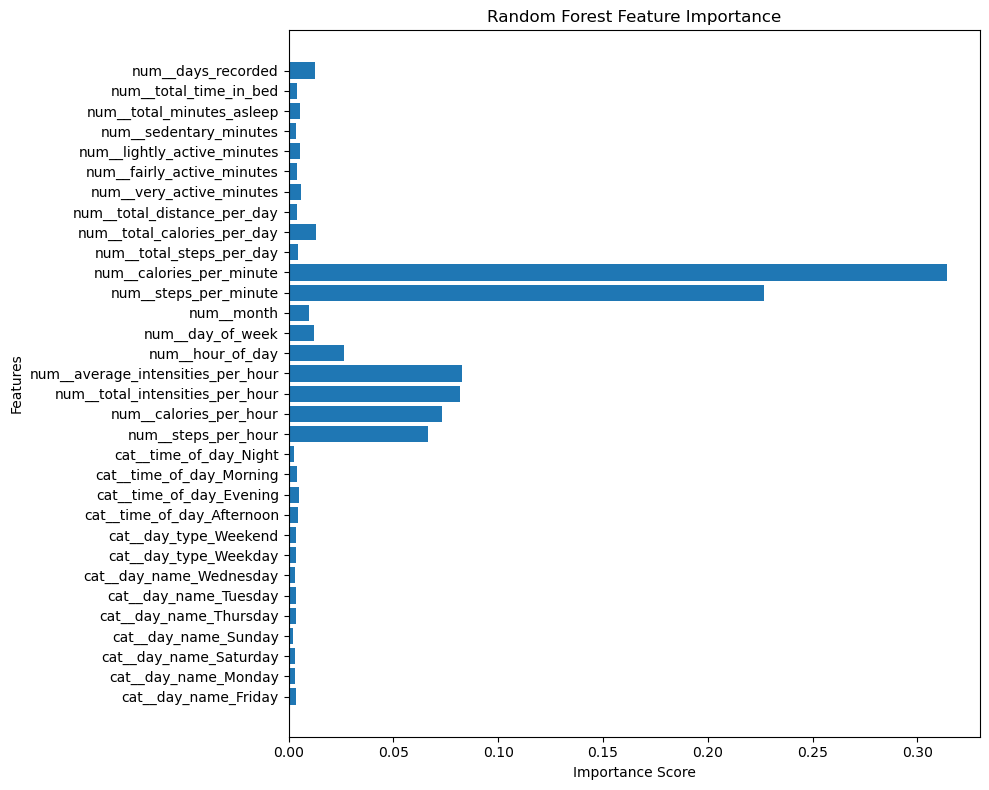

In [6]:
# Identify categorical and numeric columns
categorical_cols = ['day_name', 'day_type', 'time_of_day']
numeric_cols = ['steps_per_hour', 'calories_per_hour', 'total_intensities_per_hour', 'average_intensities_per_hour',
                'hour_of_day', 'day_of_week', 'month', 'steps_per_minute', 'calories_per_minute', 
                'total_steps_per_day', 'total_calories_per_day', 'total_distance_per_day', 'very_active_minutes',
                'fairly_active_minutes', 'lightly_active_minutes', 'sedentary_minutes', 'total_minutes_asleep',
                'total_time_in_bed', 'days_recorded']

# Preprocessing: One-hot encoding categorical columns and passing numeric variables as they are
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('num', 'passthrough', numeric_cols)
    ]
)

# Pipeline: preprocessing + model instantiation
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100, random_state=42
    ))
])

# Train-test split before model fitting with a 70% - 30% split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Fit the model
model.fit(X_train, y_train)

# Get feature names
feature_names = model.named_steps['preprocessor'].get_feature_names_out()

# Get importance
importance = model.named_steps['classifier'].feature_importances_

# Summarize feature importance
for feature, score in zip(feature_names, importance):
    print(f'Feature: {feature}, Score: {score:.5f}')

# Plot feature importance
plt.figure(figsize=(10, 8))

plt.barh(feature_names, importance)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

From the results provided above, it is clear that the categorical variables offer limited contributions according to the model. Thus, they will be removed in the feature selection process alongside any numerical values offering contributions below a specific threshold of 0.01.